### 1. Data Loading and Initial Inspection

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Configure visual settings
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# Load the dataset
file_path = '/content/KaggleV2-May-2016.csv'
df = pd.read_csv(file_path)

# Display basic information
print("Dataset Shape:", df.shape)
display(df.head())
df.info()

Dataset Shape: (110527, 14)


,PatientId,AppointmentID,Gender,ScheduledDay,AppointmentDay,Age,Neighbourhood,Scholarship,Hipertension,Diabetes,Alcoholism,Handcap,SMS_received,No-show
0,2.987250e+13,5642903,F,2016-04-29T18:38:08Z,2016-04-29T00:00:00Z,62,JARDIM DA PENHA,0,1,0,0,0,0,No
1,5.589978e+14,5642503,M,2016-04-29T16:08:27Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,0,0,0,0,0,No
2,4.262962e+12,5642549,F,2016-04-29T16:19:04Z,2016-04-29T00:00:00Z,62,MATA DA PRAIA,0,0,0,0,0,0,No
3,8.679512e+11,5642828,F,2016-04-29T17:29:31Z,2016-04-29T00:00:00Z,8,PONTAL DE CAMBURI,0,0,0,0,0,0,No
4,8.841186e+12,5642494,F,2016-04-29T16:07:23Z,2016-04-29T00:00:00Z,56,JARDIM DA PENHA,0,1,1,0,0,0,No


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 110527 entries, 0 to 110526
Data columns (total 14 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   PatientId       110527 non-null  float64
 1   AppointmentID   110527 non-null  int64  
 2   Gender          110527 non-null  object 
 3   ScheduledDay    110527 non-null  object 
 4   AppointmentDay  110527 non-null  object 
 5   Age             110527 non-null  int64  
 6   Neighbourhood   110527 non-null  object 
 7   Scholarship     110527 non-null  int64  
 8   Hipertension    110527 non-null  int64  
 9   Diabetes        110527 non-null  int64  
 10  Alcoholism      110527 non-null  int64  
 11  Handcap         110527 non-null  int64  
 12  SMS_received    110527 non-null  int64  
 13  No-show         110527 non-null  object 
dtypes: float64(1), int64(8), object(5)
memory usage: 11.8+ MB


### 2. Data Cleaning
- Standardize column names.
- Parse date columns and compute the booking window (lead time).
- Find and remove outliers (e.g., negative ages, or impossible date offsets).
- Find and drop duplicates.

In [2]:
# Clean column names (strip whitespace, correct typos like 'Hipertension' or 'Handcap')
df.columns = df.columns.str.strip().str.replace('Hipertension', 'Hypertension').str.replace('Handcap', 'Handicap')

# Convert date columns
df['ScheduledDay'] = pd.to_datetime(df['ScheduledDay'])
df['AppointmentDay'] = pd.to_datetime(df['AppointmentDay']).dt.normalize() # normalize to remove time components
df['ScheduledDay_date'] = df['ScheduledDay'].dt.normalize()

# Calculate Booking Window (waiting time in days)
df['WaitingDays'] = (df['AppointmentDay'] - df['ScheduledDay_date']).dt.days

# Find Duplicates
duplicates_count = df.duplicated().sum()
print(f"Number of exact duplicate rows: {duplicates_count}")
if duplicates_count > 0:
    df = df.drop_duplicates()

# Identify Outliers in 'Age'
print("\nAge Distribution Summary:")
print(df['Age'].describe())

# We filter out impossible ages (negative ages and ages over 115)
age_outliers = df[(df['Age'] < 0) | (df['Age'] > 115)]
print(f"\nRemoving {len(age_outliers)} age outliers (Age < 0 or Age > 115).")
df = df[(df['Age'] >= 0) & (df['Age'] <= 115)]

# Identify Outliers in WaitingDays (Appointments scheduled before the booking date are impossible)
negative_waiting = df[df['WaitingDays'] < 0]
print(f"Removing {len(negative_waiting)} rows where AppointmentDay was scheduled before ScheduledDay.")
df = df[df['WaitingDays'] >= 0]

print("\nCleaned Dataset Shape:", df.shape)

Number of exact duplicate rows: 0

Age Distribution Summary:
count    110527.000000
mean         37.088874
std          23.110205
min          -1.000000
25%          18.000000
50%          37.000000
75%          55.000000
max         115.000000
Name: Age, dtype: float64

Removing 1 age outliers (Age < 0 or Age > 115).
Removing 5 rows where AppointmentDay was scheduled before ScheduledDay.

Cleaned Dataset Shape: (110521, 16)


### 3. Exploratory Data Analysis & Visualizations

#### A. Overall No-Show Percentage

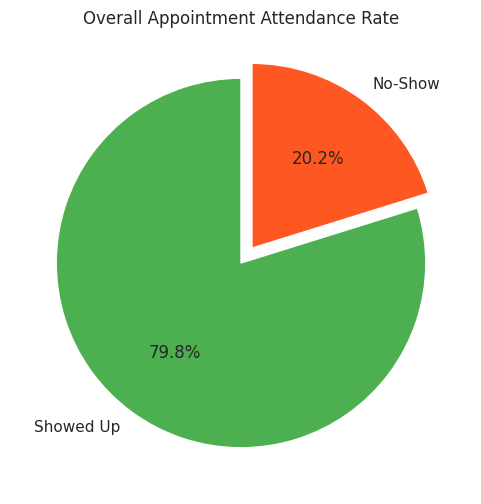

In [8]:
no_show_counts = df['No-show'].value_counts()
no_show_labels = ['Showed Up', 'No-Show']

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(no_show_counts, labels=no_show_labels, autopct='%1.1f%%', startangle=90, colors=['#4CAF50', '#FF5722'], explode=(0, 0.1))
ax.set_title('Overall Appointment Attendance Rate')
plt.show()

#### B. Age & Gender Analysis
We segment ages into categorical bins to analyze the specific demographic distribution of no-shows.

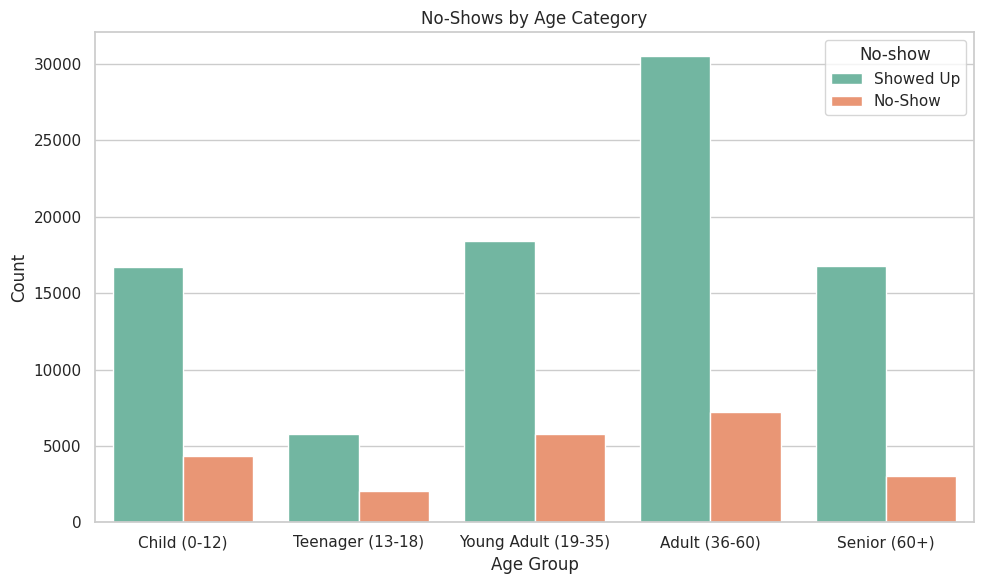

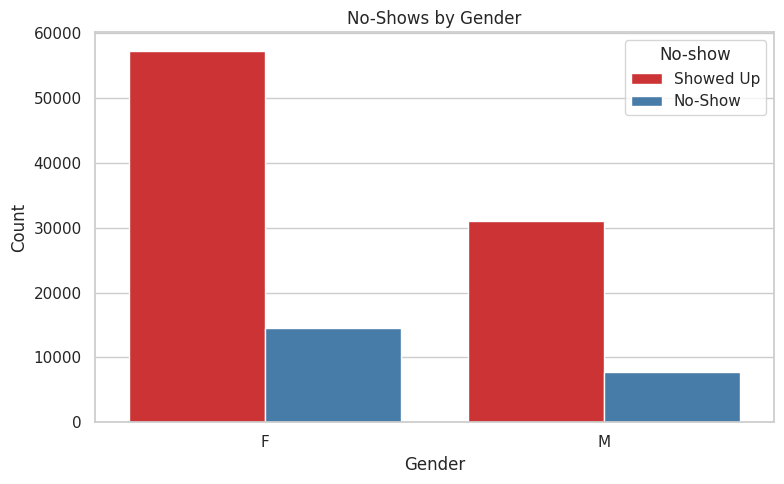

In [4]:
# Create age categories
age_bins = [0, 12, 18, 35, 60, 120]
age_labels = ['Child (0-12)', 'Teenager (13-18)', 'Young Adult (19-35)', 'Adult (36-60)', 'Senior (60+)']
df['AgeCategory'] = pd.cut(df['Age'], bins=age_bins, labels=age_labels, include_lowest=True)

# Plot Age Category vs No-show
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='AgeCategory', hue='No-show', palette='Set2')
plt.title('No-Shows by Age Category')
plt.xlabel('Age Group')
plt.ylabel('Count')
plt.legend(title='No-show', labels=['Showed Up', 'No-Show'])
plt.tight_layout()
plt.show()

# Plot Gender vs No-show
plt.figure(figsize=(8, 5))
sns.countplot(data=df, x='Gender', hue='No-show', palette='Set1')
plt.title('No-Shows by Gender')
plt.xlabel('Gender')
plt.ylabel('Count')
plt.legend(title='No-show', labels=['Showed Up', 'No-Show'])
plt.tight_layout()
plt.show()

#### C. Timing of the Booking (Waiting Window Analysis)

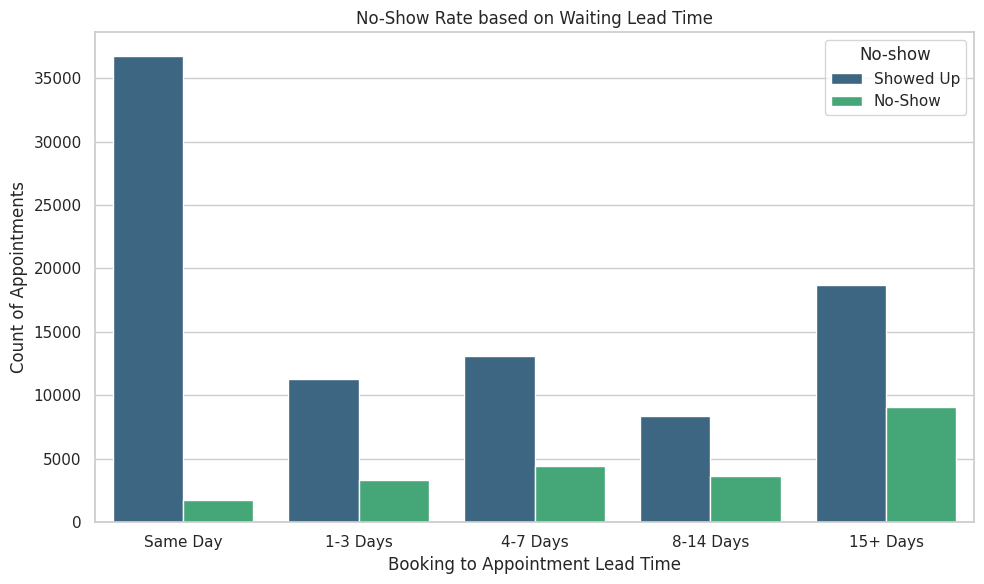

In [5]:
# Categorize the lead time/waiting days window
def categorize_waiting(days):
    if days == 0:
        return 'Same Day'
    elif days <= 3:
        return '1-3 Days'
    elif days <= 7:
        return '4-7 Days'
    elif days <= 14:
        return '8-14 Days'
    else:
        return '15+ Days'

df['WaitingCategory'] = df['WaitingDays'].apply(categorize_waiting)
waiting_order = ['Same Day', '1-3 Days', '4-7 Days', '8-14 Days', '15+ Days']

# Plot the lead time distribution vs attendance rate
plt.figure(figsize=(10, 6))
sns.countplot(data=df, x='WaitingCategory', hue='No-show', order=waiting_order, palette='viridis')
plt.title('No-Show Rate based on Waiting Lead Time')
plt.xlabel('Booking to Appointment Lead Time')
plt.ylabel('Count of Appointments')
plt.legend(title='No-show', labels=['Showed Up', 'No-Show'])
plt.tight_layout()
plt.show()

#### D. Disease Category Analysis
Comparing how specific medical conditions correlate with appointment compliance.

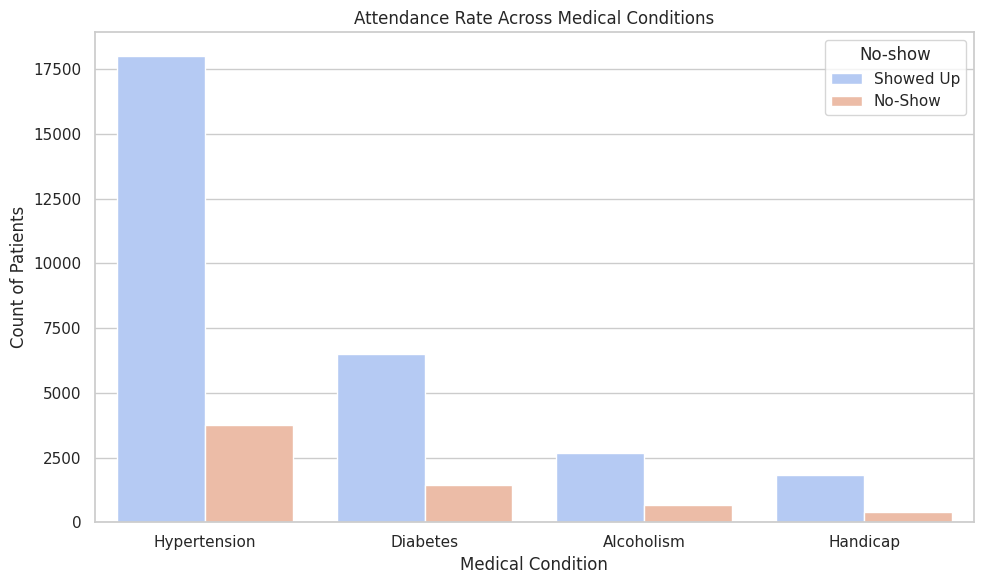

In [6]:
# List of disease categories
diseases = ['Hypertension', 'Diabetes', 'Alcoholism', 'Handicap']

melted_df = pd.melt(df, id_vars=['No-show'], value_vars=diseases,
                    var_name='Condition', value_name='HasCondition')

# Filter to only look at instances where the patient has the condition
melted_df = melted_df[melted_df['HasCondition'] > 0]

plt.figure(figsize=(10, 6))
sns.countplot(data=melted_df, x='Condition', hue='No-show', palette='coolwarm')
plt.title('Attendance Rate Across Medical Conditions')
plt.xlabel('Medical Condition')
plt.ylabel('Count of Patients')
plt.legend(title='No-show', labels=['Showed Up', 'No-Show'])
plt.tight_layout()
plt.show()

#### E. SMS Reminders vs No-Show Rates
Does sending a text reminder help reduce no-shows?

Percentage breakdown of No-Shows by SMS Status:


No-show,No,Yes
SMS_received,,
0,83.302016,16.697984
1,72.425455,27.574545


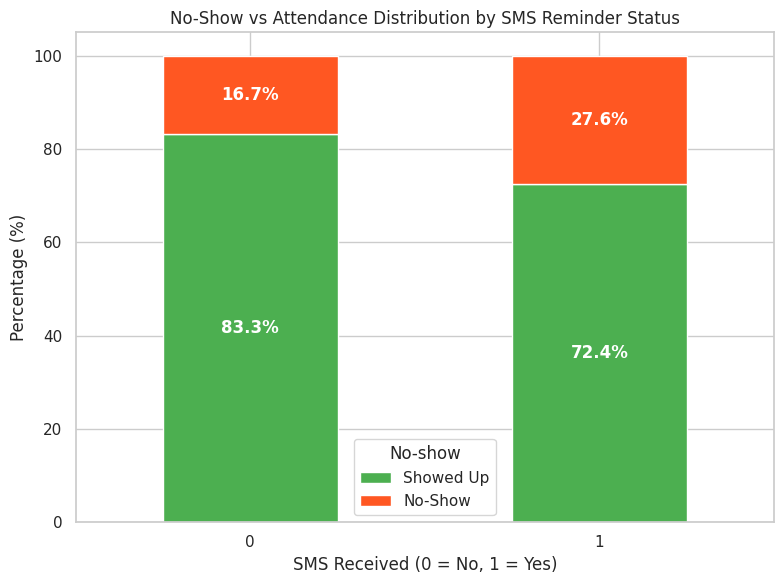

In [11]:
# Calculate proportional breakdown to visualize clearly
sms_crosstab = pd.crosstab(df['SMS_received'], df['No-show'], normalize='index') * 100
print("Percentage breakdown of No-Shows by SMS Status:")
display(sms_crosstab)

# Visualization
ax = sms_crosstab.plot(kind='bar', stacked=True, color=['#4CAF50', '#FF5722'], figsize=(8, 6))
plt.title('No-Show vs Attendance Distribution by SMS Reminder Status')
plt.xlabel('SMS Received (0 = No, 1 = Yes)')
plt.ylabel('Percentage (%)')
plt.xticks(rotation=0)
plt.legend(title='No-show', labels=['Showed Up', 'No-Show'])

# Annotating values on bars
for p in ax.patches:
    width, height = p.get_width(), p.get_height()
    x, y = p.get_xy()
    if height > 0:
        ax.text(x + width/2, y + height/2, f'{height:.1f}%',
                horizontalalignment='center', verticalalignment='center', color='white', fontweight='bold')

plt.tight_layout()
plt.show()

### 4. Additional Analysis

#### A. Average Waiting Days: Showed Up vs. No-Show
Let's analyze and visualize whether the average wait time differs significantly between those who show up and those who do not.

,No-show,WaitingDays
0,No,8.754759
1,Yes,15.835484


/tmp/ipykernel_1500/158976594.py:13: UserWarning: set_ticklabels() should only be used with a fixed number of ticks, i.e. after set_ticks() or using a FixedLocator.
  ax.set_xticklabels(['Showed Up', 'No-Show'])


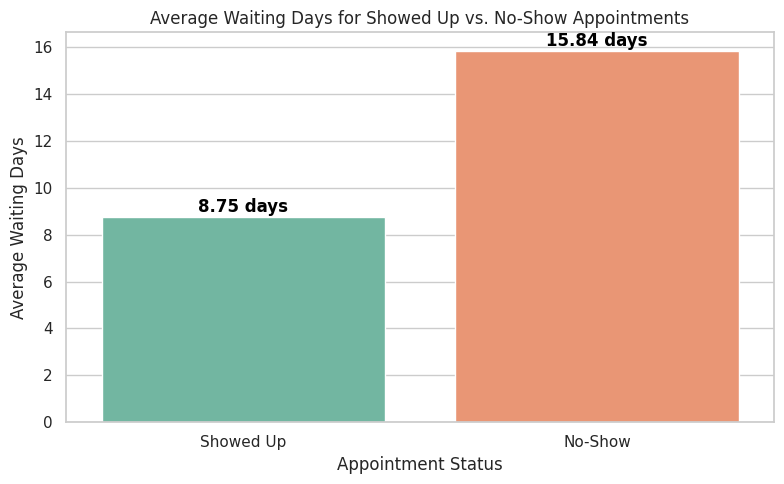

In [16]:
# Calculate average waiting days
avg_waiting = df.groupby('No-show')['WaitingDays'].mean().reset_index()
display(avg_waiting)

# Visualize average waiting days - assigned hue and legend=False to prevent seaborn future warning
plt.figure(figsize=(8, 5))
ax = sns.barplot(data=avg_waiting, x='No-show', y='WaitingDays', hue='No-show', palette='Set2', legend=False)
plt.title('Average Waiting Days for Showed Up vs. No-Show Appointments')
plt.xlabel('Appointment Status')
plt.ylabel('Average Waiting Days')

# Set ticks and corresponding labels safely to avoid warnings
ax.set_xticks(range(len(avg_waiting)))
ax.set_xticklabels(['Showed Up', 'No-Show'])

# Annotate the values
for index, row in avg_waiting.iterrows():
    plt.text(index, row['WaitingDays'] + 0.2, f"{row['WaitingDays']:.2f} days",
             color='black', ha="center", fontweight='bold')

plt.tight_layout()
plt.show()

#### B. Separate Distributions of Attendance by SMS Status
Let's view the exact distribution of Show vs. No-Show separately for patients who received the SMS and patients who did not receive the SMS.

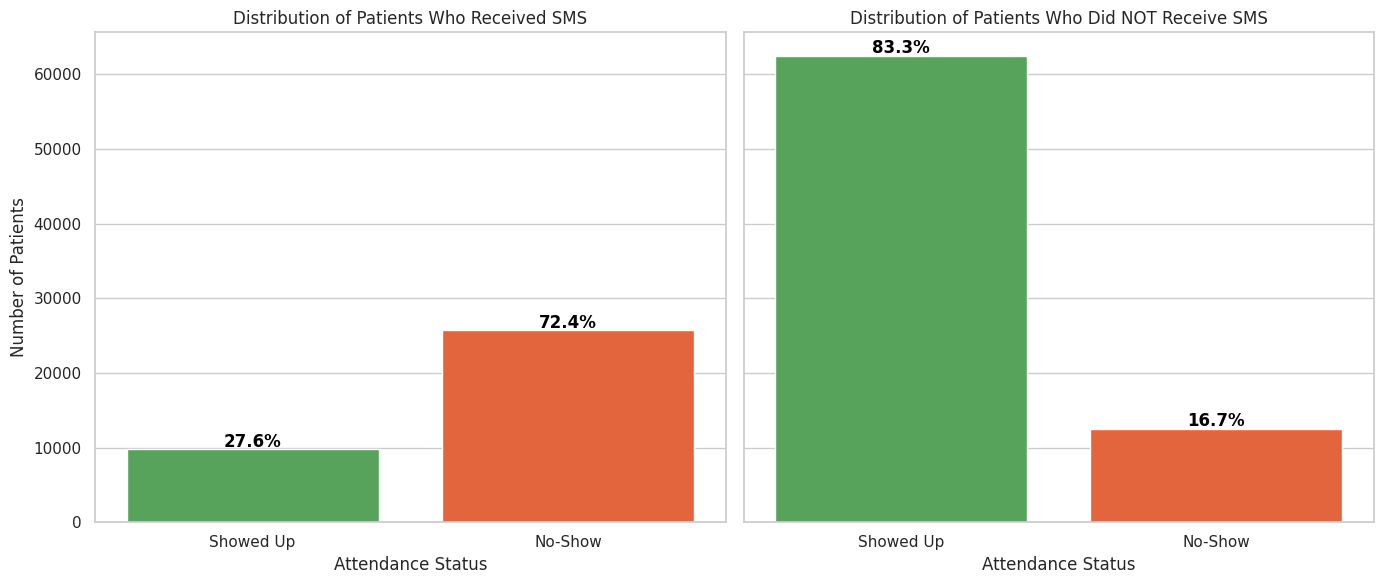

In [18]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharey=True)

# Subset data for clarity
no_sms_df = df[df['SMS_received'] == 0]
sms_df = df[df['SMS_received'] == 1]

# 1. Graph for people who got the SMS
sns.countplot(data=sms_df, x='No-show', hue='No-show', ax=axes[0], palette=['#4CAF50', '#FF5722'], legend=False)
axes[0].set_title('Distribution of Patients Who Received SMS')
axes[0].set_xlabel('Attendance Status')
axes[0].set_ylabel('Number of Patients')
axes[0].set_xticks([0, 1])
axes[0].set_xticklabels(['Showed Up', 'No-Show'])

# Add percentage labels
total_sms = len(sms_df)
for p in axes[0].patches:
    height = p.get_height()
    percentage = f'{100 * height / total_sms:.1f}%'
    axes[0].annotate(percentage, (p.get_x() + p.get_width() / 2., height + 1000),
                     ha='center', va='center', fontweight='bold', color='black')

# 2. Graph for people who DID NOT receive SMS
sns.countplot(data=no_sms_df, x='No-show', hue='No-show', ax=axes[1], palette=['#4CAF50', '#FF5722'], legend=False)
axes[1].set_title('Distribution of Patients Who Did NOT Receive SMS')
axes[1].set_xlabel('Attendance Status')
axes[1].set_ylabel('')
axes[1].set_xticks([0, 1])
axes[1].set_xticklabels(['Showed Up', 'No-Show'])

# Add percentage labels
total_no_sms = len(no_sms_df)
for p in axes[1].patches:
    height = p.get_height()
    percentage = f'{100 * height / total_no_sms:.1f}%'
    axes[1].annotate(percentage, (p.get_x() + p.get_width() / 2., height + 1000),
                     ha='center', va='center', fontweight='bold', color='black')

plt.tight_layout()
plt.show()